# 04 · Exploratory text analysis

**Guideline covered:** Exploratory text analysis

**What this notebook does.** Explores the data before and after cleaning.

*Part 1, raw data (cells A–E):* rating distribution and review length, weekly trends, the most common word pairs in complaints, company replies, app versions and data-quality checks (duplicates, unusual days).

*Part 2, cleaned text (cell X1):* text statistics per app, the words that most distinguish complaints from praise and each app's complaints from the others (weighted log-odds with an informative Dirichlet prior; Monroe, Colaresi and Quinn, 2008), word clouds and the most frequent complaint word pairs.

**Key observations**
- Unhappy users write much longer reviews: median 11 words at 1 star, 2 words at 4–5 stars. BHIM reviews have a median of 11 words, Paytm and PhonePe a median of 1.
- Complaint vocabulary is about *being blocked*: "not", "otp", "unable", "login", "account", "support". Praise is short and generic: "good", "nice", "super".
- Each app has its own complaint vocabulary (long 1–2 star reviews compared with the other apps'): BHIM "otp", "manually", "mobile data"; Paytm "environment", "alert", "device"; PhonePe "charge", "unblock"; Google Pay "reward", "suspend". This already points to the different #1 problems found in notebook 06.

**Inputs:** `raw_reviews_v2.csv`, `model_data.parquet` · **Outputs:** figures 01–03 and 15–17, `text_stats_by_app.csv`, `distinctive_words_*.csv`, `complaint_bigrams_by_app.csv`

**How to run:** open in Google Colab, keep the project folder at `MyDrive/upi-complaint-analytics` (or change `BASE` in the first code cell) and run the cells from top to bottom. The outputs shown are from the original run.

Exploratory data analysis (Phase 3)

Cell A: Load the data and print a profile

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, os
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
FIG = f'{BASE}/reports/figures'
df = pd.read_csv(f'{BASE}/data/raw/raw_reviews_v2.csv', parse_dates=['review_date', 'reply_date'])
df['review_text'] = df['review_text'].fillna('')
df['words'] = df['review_text'].str.split().str.len()
df['is_long'] = df['words'] >= 5
df['in_common'] = df['review_date'].between('2026-08-19', '2026-10-14 23:59:59')

APPS = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']
COLORS = {'BHIM': '#E4572E', 'Google Pay': '#4C9BE8', 'Paytm': '#17A398', 'PhonePe': '#7B4FBF'}

print(df.shape)
print('\nMissing values:\n', df.isna().sum())
print('\nEmpty reviews:', (df['words'] == 0).sum())
print('Same text posted twice (same app):', df.duplicated(['app', 'review_text']).sum())

summary = df.groupby('app').agg(
    reviews=('review_id', 'count'), avg_rating=('rating', 'mean'),
    pct_1_star=('rating', lambda s: (s == 1).mean() * 100),
    pct_5_star=('rating', lambda s: (s == 5).mean() * 100),
    median_words=('words', 'median'), pct_long=('is_long', lambda s: s.mean() * 100),
    pct_replied=('company_reply', lambda s: s.notna().mean() * 100),
    in_common_window=('in_common', 'sum')).round(1)
print('\n', summary)
summary.to_csv(f'{BASE}/data/processed/eda_summary.csv')

(86056, 12)

Missing values:
 app                  0
review_id            0
review_text          0
rating               0
helpful_votes        0
app_version      13040
review_date          0
company_reply    39999
reply_date       39999
words                0
is_long              0
in_common            0
dtype: int64

Empty reviews: 0
Same text posted twice (same app): 44089

             reviews  avg_rating  pct_1_star  pct_5_star  median_words  pct_long  pct_replied  in_common_window
app                                                                                                           
BHIM          10000         2.7        45.6        29.2          11.0      70.3         96.8              4406
Google Pay    18221         4.0        18.5        65.3           2.0      27.7         11.3              7992
Paytm         27614         4.5        10.4        81.2           2.0      18.2         96.2             19306
PhonePe       30221         4.4         9.3        73.7          

Cell B: rating distribution and review length

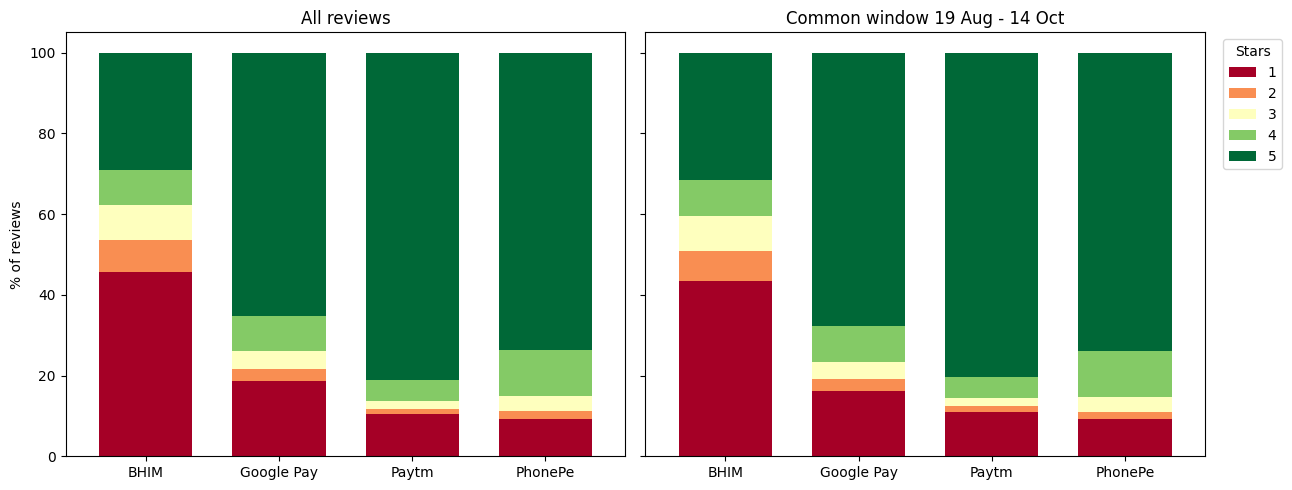

        mean  median
rating              
1       19.0    11.0
2       16.6     8.0
3       11.6     3.0
4        6.1     2.0
5        3.1     2.0


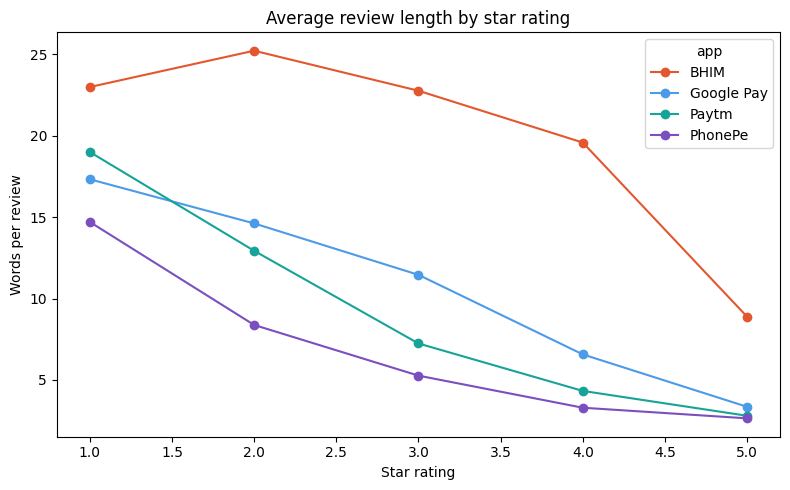

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (label, d) in zip(axes, [('All reviews', df), ('Common window 19 Aug - 14 Oct', df[df.in_common])]):
    dist = pd.crosstab(d['app'], d['rating'], normalize='index') * 100
    dist.loc[APPS].plot(kind='bar', stacked=True, ax=ax, colormap='RdYlGn', width=0.7, legend=False)
    ax.set_title(label); ax.set_xlabel(''); ax.set_ylabel('% of reviews'); ax.tick_params(axis='x', rotation=0)
axes[1].legend(title='Stars', bbox_to_anchor=(1.02, 1))
plt.tight_layout(); plt.savefig(f'{FIG}/01_rating_distribution.png', dpi=150); plt.show()

print(df.groupby('rating')['words'].agg(['mean', 'median']).round(1))
fig, ax = plt.subplots(figsize=(8, 5))
df.groupby(['rating', 'app'])['words'].mean().unstack()[APPS].plot(
    marker='o', ax=ax, color=[COLORS[a] for a in APPS])
ax.set_title('Average review length by star rating'); ax.set_xlabel('Star rating'); ax.set_ylabel('Words per review')
plt.tight_layout(); plt.savefig(f'{FIG}/02_length_by_rating.png', dpi=150); plt.show()

Cell C: Trends over time

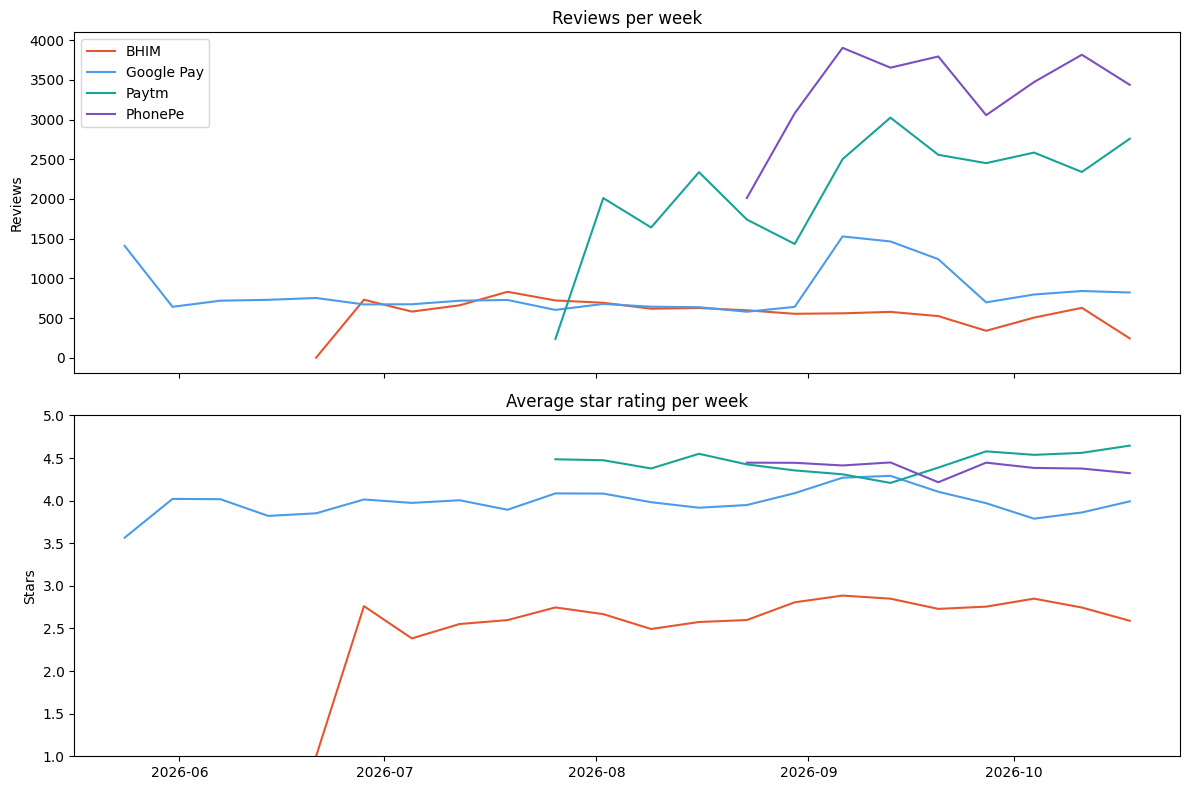

In [ ]:
weekly = (df.set_index('review_date').groupby('app')
            .resample('W')['rating'].agg(['count', 'mean']).reset_index())
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for a in APPS:
    w = weekly[weekly.app == a]
    axes[0].plot(w.review_date, w['count'], label=a, color=COLORS[a])
    axes[1].plot(w.review_date, w['mean'], label=a, color=COLORS[a])
axes[0].set_title('Reviews per week'); axes[0].set_ylabel('Reviews'); axes[0].legend()
axes[1].set_title('Average star rating per week'); axes[1].set_ylabel('Stars'); axes[1].set_ylim(1, 5)
plt.tight_layout(); plt.savefig(f'{FIG}/03_weekly_trends.png', dpi=150); plt.show()

Cell D: Most common 2 words

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
STOP = list(ENGLISH_STOP_WORDS - {'not', 'no', 'never', 'nor', 'without'})   # keep negations!

top = {}
for a in APPS:
    texts = df[(df.app == a) & (df.rating <= 2) & df.is_long]['review_text'].str.lower()
    cv = CountVectorizer(ngram_range=(2, 2), stop_words=STOP, min_df=5)
    X = cv.fit_transform(texts)
    s = pd.Series(X.sum(axis=0).A1, index=cv.get_feature_names_out()).nlargest(15)
    top[a] = [f'{k} ({v})' for k, v in s.items()]
print(pd.DataFrame(top))

                      BHIM             Google Pay                     Paytm                PhonePe
0        not working (497)       google pay (472)         not working (195)        phone pay (137)
1           not able (341)      not working (224)             app not (170)      not working (106)
2            app not (312)          app not (127)           paytm app (132)         phone pe (106)
3           bhim app (311)      bank account (89)     environment not (121)  customer support (85)
4        mobile data (284)         worst app (86)       customer care (119)         worst app (85)
5          worst app (193)          not able (76)  device environment (117)     customer care (83)
6            otp not (185)     customer care (72)         not correct (105)           app not (68)
7      mobile number (169)          upi lite (67)            worst app (96)          raha hai (63)
8          enter otp (150)           pay not (57)     customer support (87)      bank account (55)
9     unab

Cell E: Company replies and app versions

In [ ]:
!pip install -q langdetect
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0

for a in APPS:
    v = (df[df.app == a].groupby('app_version')
           .agg(reviews=('review_id', 'count'), avg_rating=('rating', 'mean'), first_seen=('review_date', 'min'))
           .query('reviews >= 300').sort_values('first_seen'))
    print(f'\n{a}: {len(v)} versions with 300+ reviews'); print(v.round(2))

r = df[df.company_reply.notna()].copy()
r['reply_hours'] = (r.reply_date - r.review_date).dt.total_seconds() / 3600
print('\nMedian hours until company reply:\n', r.groupby('app')['reply_hours'].median().round(1))
print('\nAvg rating, replied vs not:\n',
      df.assign(replied=df.company_reply.notna()).groupby(['app', 'replied'])['rating'].mean().unstack().round(2))

def lang(t):
    try: return detect(t)
    except Exception: return 'unknown'
sample = df[df.is_long].sample(3000, random_state=42)
sample['lang'] = sample.review_text.apply(lang)
print('\nLanguage mix (sample of 3,000 long reviews):\n', sample.lang.value_counts(normalize=True).head(8).round(3))


BHIM: 7 versions with 300+ reviews
             reviews  avg_rating          first_seen
app_version                                         
4.0.23           344        2.98 2026-06-21 23:57:39
4.0.24          1717        2.52 2026-06-22 00:09:24
4.0.25           475        3.13 2026-07-08 15:02:53
4.0.26          2467        2.62 2026-07-19 16:35:36
4.0.27           786        3.03 2026-08-18 18:16:20
4.0.29          1089        2.87 2026-09-08 13:00:57
4.0.30           456        2.60 2026-09-27 11:50:16

Google Pay: 16 versions with 300+ reviews
                                     reviews  avg_rating          first_seen
app_version                                                                 
331.1.2 (arm64-v8a_release_flutter)     1107        3.62 2026-05-18 08:45:19
332.1.1 (arm64-v8a_release_flutter)      519        4.06 2026-05-21 10:25:11
333.1.1 (arm64-v8a_release_flutter)      496        3.91 2026-05-26 07:53:31
335.1.2 (arm64-v8a_release_flutter)      775        3.92 20

In [ ]:
# Check 1: long reviews that appear more than once (possible spam / copy-paste)
long_dup = df[df.is_long & df.duplicated(['app', 'review_text'], keep=False)]
print('Long reviews appearing more than once:', len(long_dup))
print(long_dup.review_text.value_counts().head(10))

# Check 2: Google Pay's first week, day by day
g = df[(df.app == 'Google Pay') & (df.review_date < '2026-05-26')]
print(g.groupby(g.review_date.dt.date).agg(reviews=('rating', 'size'), avg_rating=('rating', 'mean')).round(2))

# Check 3: are company replies templates? (few unique texts = automated)
rep = df[df.company_reply.notna()]
print(rep.groupby('app').company_reply.agg(replies='size', unique_reply_texts='nunique'))
print(rep[rep.app == 'Paytm'].company_reply.value_counts().head(3))

Long reviews appearing more than once: 104
review_text
this app is very good                         7
best app for online payment                   6
best app for money transfer                   4
nice app easy to use                          4
app is not working properly                   4
best app for upi payment                      3
one of the best app                           2
Outstanding app with extraordinary service    2
very very very nice app                       2
fast and easy to use                          2
Name: count, dtype: int64
             reviews  avg_rating
review_date                     
2026-05-18       472        3.38
2026-05-19       327        3.35
2026-05-20       171        3.58
2026-05-21       129        3.55
2026-05-22       108        3.95
2026-05-23        97        4.09
2026-05-24       105        4.13
2026-05-25        69        3.70
            replies  unique_reply_texts
app                                    
BHIM           9684          

## Part 2: exploratory analysis of the cleaned text (cell X1)
Which words separate complaints from praise, and one app's complaints from the others? Uses `text_full` from notebook 02.

       app  reviews  median_words  mean_words  pct_5plus_words  tokens_after_cleaning  vocabulary_size  pct_with_emoji  pct_with_negation  pct_mentioning_money
      BHIM     9916          11.0        18.7             70.1                 100143             5560             9.0               44.5                  11.2
Google Pay    17979           2.0         6.8             27.4                  68670             6603            14.2               15.3                   6.8
     Paytm    27329           1.0         4.6             17.7                  74036             6356            17.1                9.0                   3.2
   PhonePe    29926           1.0         3.9             16.1                  69822             6800            13.0                6.1                   3.3

Median words by star rating: {1: 11.0, 2: 8.0, 3: 3.0, 4: 2.0, 5: 1.0}


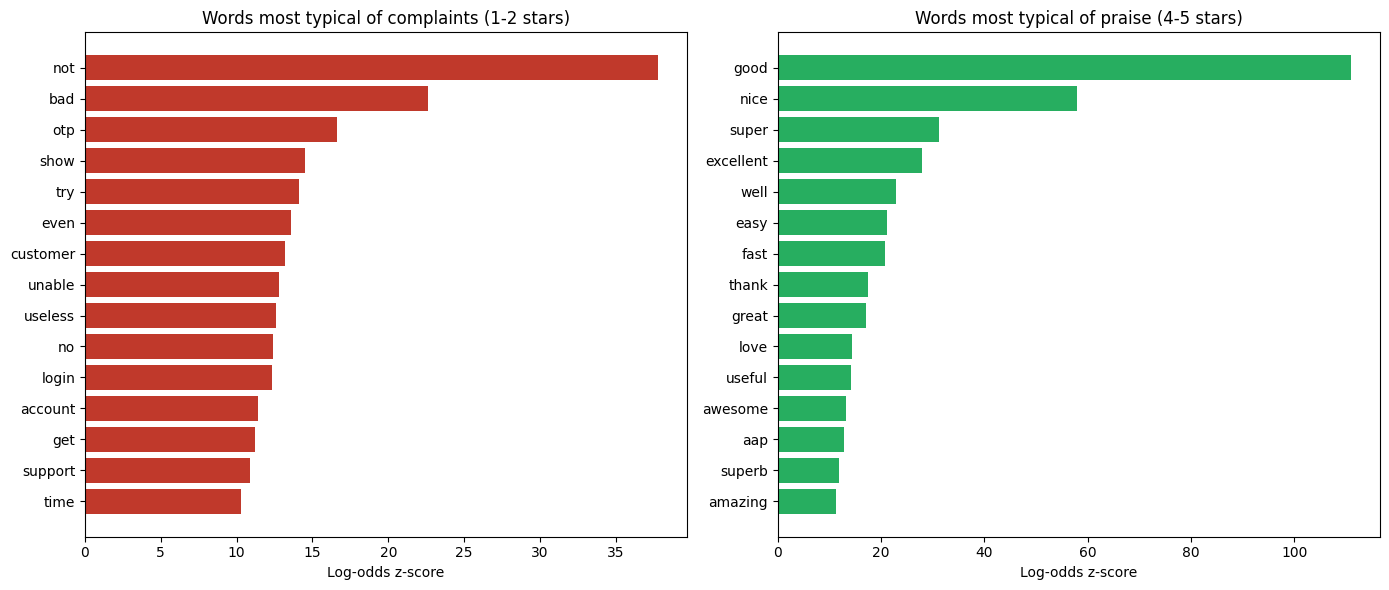

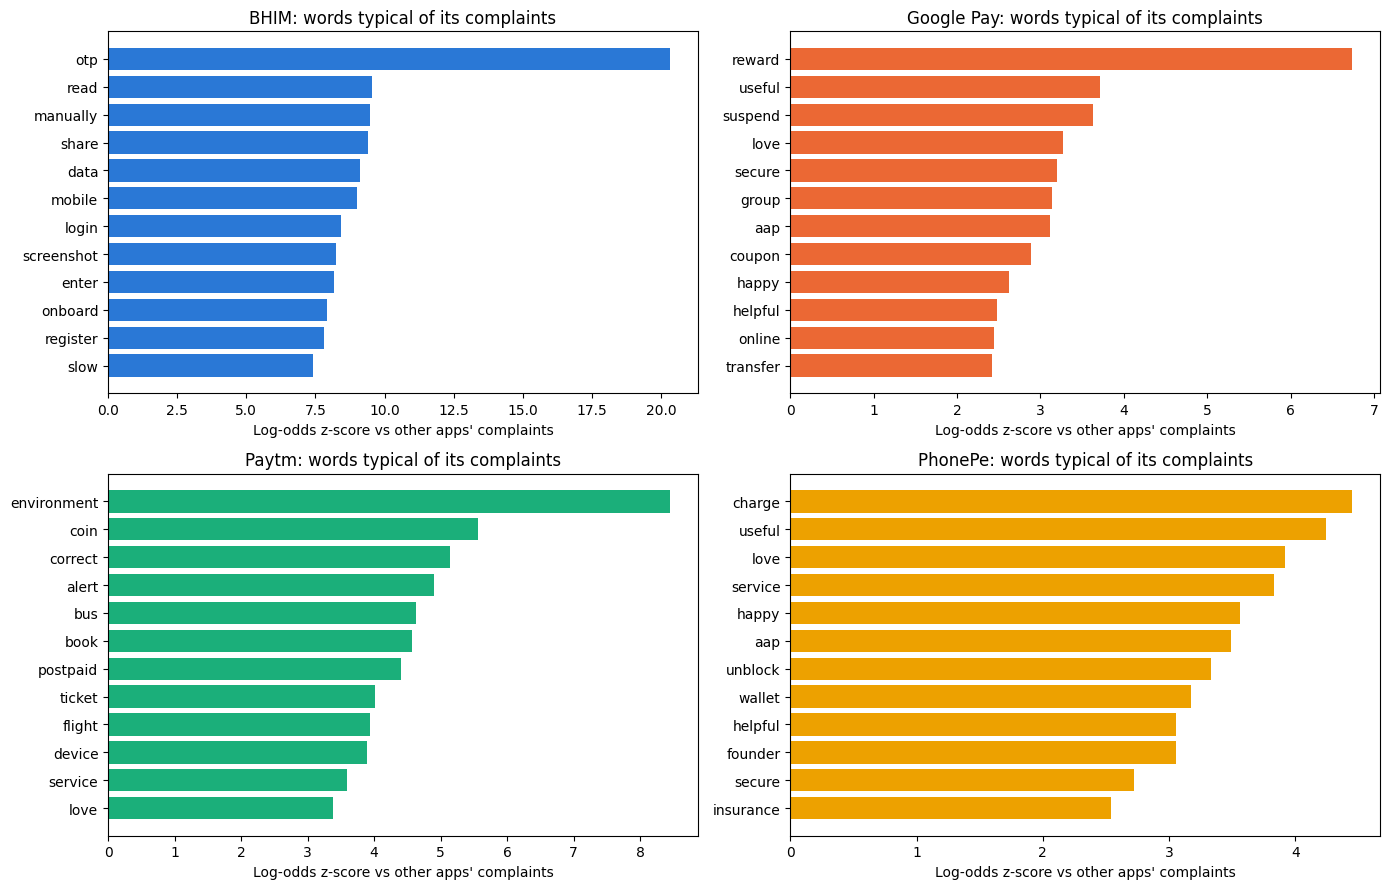

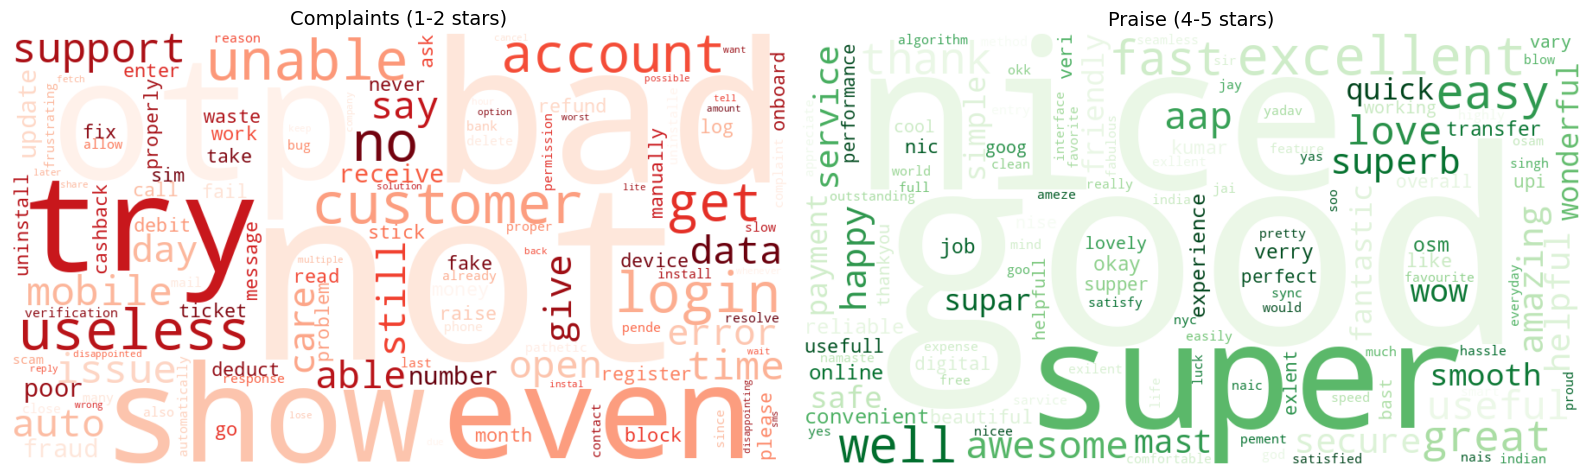


Top complaint word pairs per app:
       app             bigram  count
      BHIM           not work    735
      BHIM           not able    368
      BHIM        mobile data    284
      BHIM            otp not    274
      BHIM          enter otp    177
      BHIM      mobile number    170
Google Pay           not work    390
Google Pay            not use    103
Google Pay       bank account     97
Google Pay           not open     96
Google Pay           not able     90
Google Pay           not show     87
     Paytm           not work    296
     Paytm           not open    141
     Paytm    environment not    122
     Paytm      customer care    121
     Paytm device environment    117
     Paytm        not correct    106
   PhonePe           not work    159
   PhonePe   customer support     89
   PhonePe      customer care     89
   PhonePe            not use     82
   PhonePe     bad experience     78
   PhonePe       bank account     60


In [16]:
# ===== Phase 3b – Exploratory text analysis =====
# Cell X1: what do the review texts look like, and which words separate complaints from praise, and one app from another?
# Distinctive words use the weighted log-odds ratio with an informative Dirichlet prior (Monroe, Colaresi & Quinn, 2008):
# a z-score per word; large positive = typical of the first group, large negative = typical of the second group.
!pip install -q wordcloud
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud

BASE = '/content/drive/MyDrive/upi-complaint-analytics'
PROC, REP, FIG = f'{BASE}/data/processed', f'{BASE}/reports', f'{BASE}/reports/figures'
APPS = ['BHIM', 'Google Pay', 'Paytm', 'PhonePe']
COL = {'BHIM': '#2a78d6', 'Google Pay': '#eb6834', 'Paytm': '#1baf7a', 'PhonePe': '#eda100'}

data = pd.read_parquet(f'{PROC}/model_data.parquet')
data['tokens'] = data.text_full.fillna('').str.split()

# --- 1. Text statistics per app
rows = []
for a in APPS:
    s = data[data.app == a]
    words = [w for ws in s.tokens for w in ws]
    rows.append({'app': a, 'reviews': len(s), 'median_words': s.n_words.median(), 'mean_words': round(s.n_words.mean(), 1),
                 'pct_5plus_words': round((s.n_words >= 5).mean() * 100, 1), 'tokens_after_cleaning': len(words),
                 'vocabulary_size': len(set(words)), 'pct_with_emoji': round((s.n_emojis > 0).mean() * 100, 1),
                 'pct_with_negation': round(s.has_negation.mean() * 100, 1),
                 'pct_mentioning_money': round(s.has_money.mean() * 100, 1)})
text_stats = pd.DataFrame(rows)
text_stats.to_csv(f'{REP}/text_stats_by_app.csv', index=False)
print(text_stats.to_string(index=False))
print('\nMedian words by star rating:', data.groupby('rating').n_words.median().to_dict())

# --- 2. Distinctive words: complaints (1-2 stars) vs praise (4-5 stars)
prior = Counter(w for ws in data.tokens for w in ws)
def log_odds_z(g1, g2, min_count=20):
    c1, c2 = Counter(w for ws in g1 for w in ws), Counter(w for ws in g2 for w in ws)
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    out = {}
    for w in set(c1) | set(c2):
        if c1[w] + c2[w] < min_count:
            continue
        aw = prior[w]
        d = np.log((c1[w] + aw) / (n1 + a0 - c1[w] - aw)) - np.log((c2[w] + aw) / (n2 + a0 - c2[w] - aw))
        out[w] = d / np.sqrt(1 / (c1[w] + aw) + 1 / (c2[w] + aw))
    return pd.Series(out).sort_values()

z = log_odds_z(data[data.rating <= 2].tokens, data[data.rating >= 4].tokens)
dist = pd.concat([z.tail(20)[::-1].rename('z').to_frame().assign(group='complaints (1-2 stars)'),
                  z.head(20).rename('z').to_frame().assign(group='praise (4-5 stars)')]).rename_axis('word').reset_index()
dist.to_csv(f'{REP}/distinctive_words_sentiment.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (g, sub), color in zip(axes, dist.groupby('group', sort=False), ['#c0392b', '#27ae60']):
    sub = sub.head(15).iloc[::-1]
    ax.barh(sub.word, sub.z.abs(), color=color)
    ax.set_title(f'Words most typical of {g}'); ax.set_xlabel('Log-odds z-score')
plt.tight_layout(); plt.savefig(f'{FIG}/15_distinctive_words_sentiment.png', dpi=150); plt.show()

# --- 3. Distinctive complaint words per app (each app's long 1-2 star reviews vs the other apps' long 1-2 star reviews)
# Generic opinion words are left out here: short complaints like "not good" would otherwise dominate.
neg = data[data.rating <= 2]
GENERIC = {'good', 'nice', 'super', 'excellent', 'well', 'easy', 'fast', 'great', 'thank', 'best', 'bad', 'worst',
           'app', 'very', 'use', 'not', 'no', 'pay', 'payment', 'money', 'google', 'paytm', 'phonepe', 'bhim'}
negl = neg[neg.n_words >= 5]
tok_f = negl.tokens.map(lambda ws: [w for w in ws if w not in GENERIC])
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
per_app = []
for ax, a in zip(axes.ravel(), APPS):
    za = log_odds_z(tok_f[negl.app == a], tok_f[negl.app != a], min_count=15).tail(12)
    per_app.append(za.rename('z').to_frame().assign(app=a).rename_axis('word').reset_index())
    ax.barh(za.index, za.values, color=COL[a]); ax.set_title(f'{a}: words typical of its complaints')
    ax.set_xlabel('Log-odds z-score vs other apps\' complaints')
pd.concat(per_app).to_csv(f'{REP}/distinctive_words_by_app.csv', index=False)
plt.tight_layout(); plt.savefig(f'{FIG}/16_distinctive_words_by_app.png', dpi=150); plt.show()

# --- 4. Word clouds weighted by distinctiveness (not raw frequency, which only shows "good" and "app")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (title, weights, cmap) in zip(axes, [('Complaints (1-2 stars)', z[z > 0].tail(120), 'Reds'),
                                             ('Praise (4-5 stars)', -z[z < 0].head(120), 'Greens')]):
    wc = WordCloud(width=900, height=500, background_color='white', colormap=cmap, random_state=42)
    ax.imshow(wc.generate_from_frequencies(weights.to_dict()), interpolation='bilinear')
    ax.set_title(title, fontsize=14); ax.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG}/17_wordclouds.png', dpi=150); plt.show()

# --- 5. Most common word pairs (bigrams) in each app's complaints
bi = []
for a in APPS:
    c = Counter(f'{x} {y}' for ws in neg[neg.app == a].tokens for x, y in zip(ws, ws[1:]))
    bi += [{'app': a, 'bigram': b, 'count': n} for b, n in c.most_common(10)]
bi = pd.DataFrame(bi)
bi.to_csv(f'{REP}/complaint_bigrams_by_app.csv', index=False)
print('\nTop complaint word pairs per app:')
print(bi.groupby('app').head(6).to_string(index=False))